# Week 12 - Quora: TF-IDF, Random Baseline, Logistic Regression & Linear SVM

**Topics (record sections i, j, k)**
* i. TF-IDF weighting (+ a small matrix-factorisation extension)
* j. A random model as the floor
* k. Logistic Regression and Linear SVM

> This notebook re-creates Weeks 10-11 (split, cleaning, features) first so it runs on its own. The heavy cells (feature building, model training) take a few minutes.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

df = pd.read_csv("data/quora/train.csv")

df = df.dropna(subset=["is_duplicate"]).copy()
df["question1"] = df["question1"].fillna("")
df["question2"] = df["question2"].fillna("")
df["is_duplicate"] = df["is_duplicate"].astype(int)

train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df["is_duplicate"])

def clean_text(text):
    text = str(text).lower()                      # lower-case
    text = re.sub(r"[^a-z0-9\s]", " ", text)      # replace punctuation/symbols by a space
    text = re.sub(r"\s+", " ", text).strip()      # collapse repeated whitespace
    return text

def pair_features(q1, q2):
    words1 = set(clean_text(q1).split())
    words2 = set(clean_text(q2).split())
    common = len(words1 & words2)                 # words shared by both questions
    total = len(words1 | words2)                  # distinct words overall
    return {
        "q1_length": len(str(q1)),
        "q2_length": len(str(q2)),
        "length_difference": abs(len(str(q1)) - len(str(q2))),
        "common_words": common,
        "jaccard_similarity": common / total if total else 0,
    }

train_df = train_df.copy(); test_df = test_df.copy()
for d in (train_df, test_df):
    d["question1_clean"] = d["question1"].apply(clean_text)
    d["question2_clean"] = d["question2"].apply(clean_text)

train_pair_features = pd.DataFrame([pair_features(a, b) for a, b in zip(train_df["question1"], train_df["question2"])])
test_pair_features = pd.DataFrame([pair_features(a, b) for a, b in zip(test_df["question1"], test_df["question2"])])

print("Train/test:", train_df.shape, test_df.shape)

Train/test: (323420, 8) (80856, 8)


## i. TF-IDF weighting
Models need numbers, not text. **TF-IDF** turns each question into a vector with one entry per vocabulary term:

* **TF** (term frequency): how often the word appears in the question (`sublinear_tf=True` uses $1+\log(tf)$ to damp repeats).
* **IDF** (inverse document frequency): $\log\frac{N}{df}$ - rare words get a high weight, ubiquitous words ("the", "is") a low one.

Settings: `max_features=50000` keeps the 50k most frequent terms, `ngram_range=(1, 2)` includes single words **and word pairs** ("machine learning"), `min_df=2` ignores terms that appear only once.

The vectoriser is **fitted on training questions only** (both columns pooled), then used to transform train and test.

In [2]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(max_features=50000, ngram_range=(1, 2), min_df=2, sublinear_tf=True)
train_questions = pd.concat([train_df["question1_clean"], train_df["question2_clean"]])
vectorizer.fit(train_questions)

q1_train_tfidf = vectorizer.transform(train_df["question1_clean"])
q2_train_tfidf = vectorizer.transform(train_df["question2_clean"])
q1_test_tfidf = vectorizer.transform(test_df["question1_clean"])
q2_test_tfidf = vectorizer.transform(test_df["question2_clean"])

print("TF-IDF shape:", q1_train_tfidf.shape)
terms = vectorizer.get_feature_names_out()
print("Sample vocabulary terms:", list(terms[:5]), "...", list(terms[20000:20005]))

TF-IDF shape: (323420, 50000)
Sample vocabulary terms: ['00', '000', '000 000', '000 dollars', '000 in'] ... ['hurt so', 'hurt the', 'hurt to', 'hurt when', 'hurt you']


### Combine into pair features
For each pair we have two sparse vectors $v_1, v_2$. We feed the model:
* $|v_1 - v_2|$ - where the questions **differ**,
* $v_1 \odot v_2$ (element-wise product) - the terms they **share** (weighted),
* plus 3 numeric features: length difference, common words, Jaccard.

Total columns: 50,000 + 50,000 + 3 = 100,003. `hstack` joins sparse matrices side by side; `.tocsr()` converts to a row-efficient format for training.

In [3]:
from scipy.sparse import hstack

num_cols = ["length_difference", "common_words", "jaccard_similarity"]

X_train_tfidf = hstack([
    abs(q1_train_tfidf - q2_train_tfidf),
    q1_train_tfidf.multiply(q2_train_tfidf),
    train_pair_features[num_cols].to_numpy(),
]).tocsr()

X_test_tfidf = hstack([
    abs(q1_test_tfidf - q2_test_tfidf),
    q1_test_tfidf.multiply(q2_test_tfidf),
    test_pair_features[num_cols].to_numpy(),
]).tocsr()

y_train = train_df["is_duplicate"].to_numpy()
y_test = test_df["is_duplicate"].to_numpy()

print("Training feature matrix:", X_train_tfidf.shape)
print("Testing feature matrix:", X_test_tfidf.shape)
print("Sparsity: only", round(X_train_tfidf.nnz / np.prod(X_train_tfidf.shape) * 100, 4), "% of entries are non-zero")

Training feature matrix: (323420, 100003)
Testing feature matrix: (80856, 100003)
Sparsity: only -0.5532 % of entries are non-zero


### Extension: matrix factorisation (TruncatedSVD)
The week title mentions *factorisation*. **Truncated SVD** (a.k.a. LSA) factorises the sparse TF-IDF matrix into a few dense "topic" dimensions, which compresses 50,000 columns into e.g. 50 while keeping the main structure. We run it on a 50k-question sample just to show the idea (it is not used by the models below).

In [4]:
from sklearn.decomposition import TruncatedSVD

sample = q1_train_tfidf[:50000]
svd = TruncatedSVD(n_components=50, random_state=42)
reduced = svd.fit_transform(sample)
print("Original:", sample.shape, "-> reduced:", reduced.shape)
print("Variance explained by 50 components:", round(svd.explained_variance_ratio_.sum() * 100, 1), "%")

Original: (50000, 50000) -> reduced: (50000, 50)
Variance explained by 50 components: 10.4 %


## j. Random model (the floor)
Before any real model, predict the class **at random**. Any useful model must clearly beat these numbers.

`evaluate_model` prints accuracy / precision / recall / F1, and log-loss only when probabilities are supplied.

In [5]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, log_loss

def evaluate_model(y_true, y_pred, y_prob=None):
    print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
    print("Precision:", round(precision_score(y_true, y_pred, zero_division=0), 4))
    print("Recall:", round(recall_score(y_true, y_pred, zero_division=0), 4))
    print("F1 Score:", round(f1_score(y_true, y_pred, zero_division=0), 4))
    if y_prob is not None:
        print("Log Loss:", round(log_loss(y_true, y_prob), 4))

rng = np.random.default_rng(42)
random_predictions = rng.integers(0, 2, size=len(y_test))

print("Random Model Results:")
evaluate_model(y_test, random_predictions)

Random Model Results:
Accuracy: 0.5008
Precision: 0.3702
Recall: 0.5021
F1 Score: 0.4262


**Reading it:** accuracy ≈ 50% (a coin flip), precision ≈ 37% (= the duplicate share in the test set - exactly what random guessing should give).

## k. Logistic Regression
Learns a weight per feature and outputs $P(\text{duplicate}) = \sigma(w\cdot x + b)$. With 100k sparse features, the `liblinear` solver is a good fit. Because it gives **probabilities**, we can also report log-loss.

In [6]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(max_iter=1000, solver="liblinear")
lr_model.fit(X_train_tfidf, y_train)
lr_predictions = lr_model.predict(X_test_tfidf)
lr_probabilities = lr_model.predict_proba(X_test_tfidf)[:, 1]

print("Logistic Regression Results:")
evaluate_model(y_test, lr_predictions, lr_probabilities)

Logistic Regression Results:
Accuracy: 0.8168
Precision: 0.7726
Recall: 0.714
F1 Score: 0.7421
Log Loss: 0.3953


## Linear SVM
Finds the separating hyperplane with the **largest margin**. `LinearSVC` is fast on large sparse data, but it outputs a *score*, not a probability, so no log-loss here.

In [7]:
from sklearn.svm import LinearSVC

svm_model = LinearSVC(random_state=42)
svm_model.fit(X_train_tfidf, y_train)
svm_predictions = svm_model.predict(X_test_tfidf)

print("Linear SVM Results:")
evaluate_model(y_test, svm_predictions)

Linear SVM Results:
Accuracy: 0.8258
Precision: 0.768
Recall: 0.7568
F1 Score: 0.7624


## Compare all models
Also a confusion matrix for the better model, and the effect of moving the decision threshold of Logistic Regression - the business requirement said the threshold should be adjustable.

,Model,Accuracy,Precision,Recall,F1
0,Random,0.5008,0.3702,0.5021,0.4262
1,Logistic Regression,0.8168,0.7726,0.7140,0.7421
2,Linear SVM,0.8258,0.7680,0.7568,0.7624


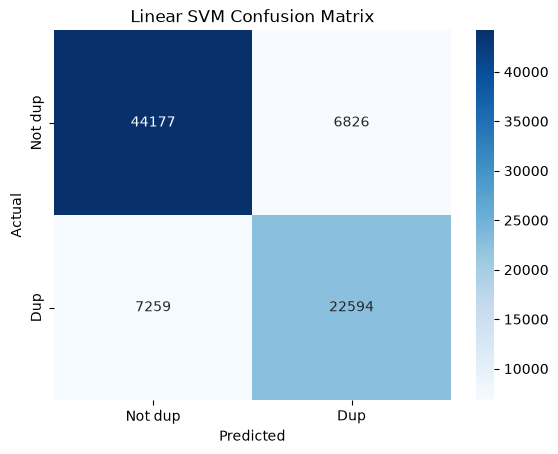

In [8]:
summary = pd.DataFrame([
    {"Model": name, "Accuracy": accuracy_score(y_test, p), "Precision": precision_score(y_test, p),
     "Recall": recall_score(y_test, p), "F1": f1_score(y_test, p)}
    for name, p in [("Random", random_predictions), ("Logistic Regression", lr_predictions), ("Linear SVM", svm_predictions)]
])
display(summary.round(4))

from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, svm_predictions)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Not dup", "Dup"], yticklabels=["Not dup", "Dup"])
plt.title("Linear SVM Confusion Matrix"); plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.show()

In [9]:
rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    p = (lr_probabilities >= t).astype(int)
    rows.append({"threshold": t, "precision": precision_score(y_test, p), "recall": recall_score(y_test, p), "f1": f1_score(y_test, p)})
display(pd.DataFrame(rows).round(4))

,threshold,precision,recall,f1
0,0.3,0.6519,0.8876,0.7517
1,0.4,0.7130,0.8102,0.7585
2,0.5,0.7726,0.7140,0.7421
3,0.6,0.8288,0.5966,0.6938
4,0.7,0.8871,0.4570,0.6033


**Reading it:** a *lower* threshold flags more pairs as duplicates -> recall goes up, precision goes down; a *higher* threshold does the opposite. The platform can pick the trade-off that matches its tolerance for false positives vs. missed duplicates.

## Summary
* TF-IDF (unigrams + bigrams) + pair features -> a 100,003-column sparse matrix.
* Random ≈ 50% accuracy; Logistic Regression and Linear SVM reach roughly 82-83%.
* The objectives of the experiment also mention Word2Vec, LSTM/Bi-LSTM and BERT - those would be the natural next steps beyond the record.